# Olist E-commerce Analysis: Growth, Retention and Delivery Experience

**Business question:** Olist, a Brazilian online marketplace, grew fast in 2017-2018. Where does revenue come from, do customers come back, and what is hurting customer satisfaction?

**Data:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle). 99,441 orders across 8 related tables: orders, customers, items, payments, reviews, products, sellers and category names.

**Scope:** delivered orders, January 2017 to August 2018 (complete months). Revenue = item price + freight, in Brazilian reais (BRL).

**Approach:** all metrics are calculated in SQL (DuckDB) using joins, CTEs and window functions. Python is used only for charts. Every query is in `sql/01_analysis_queries.sql`.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
IMG = "../images/"

con = duckdb.connect()
for stmt in open("../sql/00_load_tables.sql").read().replace("'data/", "'../data/").split(";"):
    if "CREATE" in stmt:
        con.execute(stmt)

# Split the query file into numbered queries: run(5) runs "Q5"
queries = {}
for block in open("../sql/01_analysis_queries.sql").read().split(";"):
    if "SELECT" in block:
        n = int(block.split("-- Q")[1].split(".")[0])
        queries[n] = block

def run(n):
    title = queries[n].split("-- Q")[1].split("\n")[0]
    print("Q" + title)
    return con.execute(queries[n]).df()

for t in ["orders", "customers", "order_items", "order_payments", "order_reviews", "products", "sellers"]:
    print(f"{t:15s}", con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0], "rows")

orders          99441 rows
customers       99441 rows
order_items     112650 rows
order_payments  103886 rows
order_reviews   99224 rows
products        32951 rows
sellers         3095 rows


## 1. Data quality checks

In [2]:
con.execute("""
SELECT
  SUM(CASE WHEN order_delivered_customer_date IS NULL AND order_status = 'delivered' THEN 1 ELSE 0 END) AS delivered_without_date,
  (SELECT COUNT(*) - COUNT(DISTINCT order_id) FROM orders)                                                AS duplicate_order_ids,
  (SELECT COUNT(*) FROM products WHERE product_category_name IS NULL)                                    AS products_without_category,
  (SELECT COUNT(*) FROM order_reviews WHERE review_score NOT BETWEEN 1 AND 5)                            AS invalid_review_scores
FROM orders
""").df()

,delivered_without_date,duplicate_order_ids,products_without_category,invalid_review_scores
0,8.0,0,610,0


The data is in good shape. A handful of delivered orders lack a delivery date (excluded from delivery analysis) and 610 products have no category (shown as "unknown"). Customers are identified by `customer_unique_id`, because `customer_id` changes with every order.

## 2. Headline KPIs and growth

In [3]:
run(1)

Q1. Headline KPIs


,orders,customers,revenue_brl,avg_order_value_brl
0,96211,93104,15373120.0,159.79


Q2. Monthly revenue, orders and month-on-month growth (LAG)


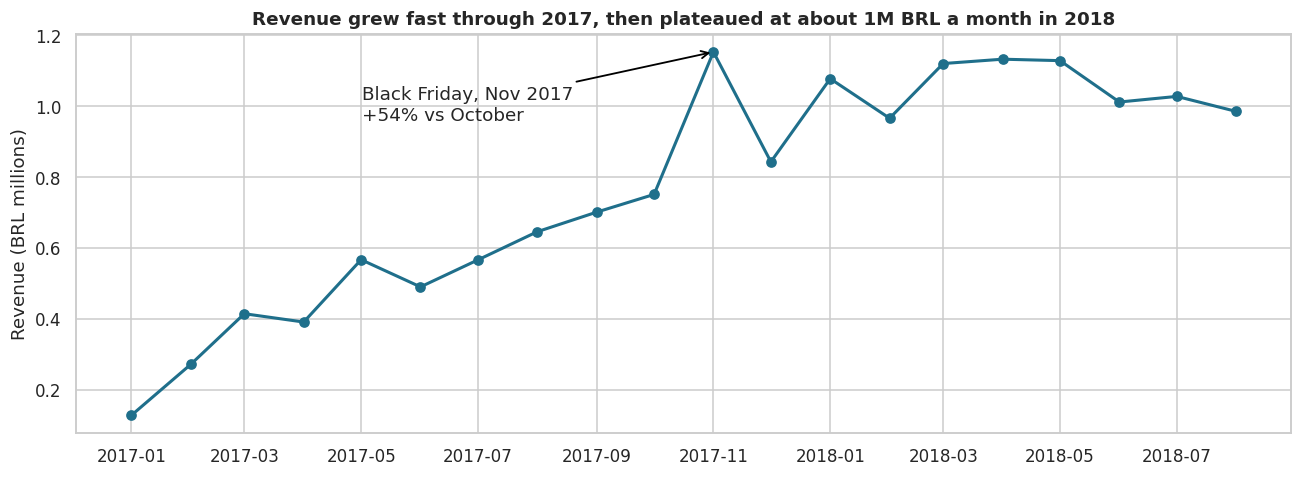

Jan-Aug revenue: 2017 = 3,472,896 BRL, 2018 = 8,451,584 BRL, growth = 143%


In [4]:
monthly = run(2)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly.month, monthly.revenue_brl / 1e6, marker="o", color="#1f6f8b", lw=2)
peak = monthly.loc[monthly.revenue_brl.idxmax()]
ax.annotate("Black Friday, Nov 2017\n+54% vs October", xy=(mdates.date2num(peak.month), peak.revenue_brl / 1e6),
            xytext=(-230, -45), textcoords="offset points", arrowprops=dict(arrowstyle="->", color="black", lw=1.2))
ax.set_ylabel("Revenue (BRL millions)"); ax.set_xlabel("")
ax.set_title("Revenue grew fast through 2017, then plateaued at about 1M BRL a month in 2018", fontweight="bold")
plt.tight_layout(); plt.savefig(IMG + "01_monthly_revenue.png", bbox_inches="tight"); plt.show()

m = monthly.assign(year=monthly.month.dt.year, mon=monthly.month.dt.month)
jan_aug = m[m.mon <= 8].groupby("year").revenue_brl.sum()
print(f"Jan-Aug revenue: 2017 = {jan_aug[2017]:,.0f} BRL, 2018 = {jan_aug[2018]:,.0f} BRL, growth = {jan_aug[2018]/jan_aug[2017]-1:.0%}")

**Finding 1:** Revenue grew from about 0.13M BRL (Jan 2017) to about 1.1M BRL a month, and January-August 2018 revenue was well over double the same period in 2017. But growth flattened through 2018: monthly revenue moved sideways from January to August. Black Friday (November 2017) was the single biggest month.

Q3. Top 10 categories by revenue with share and running total


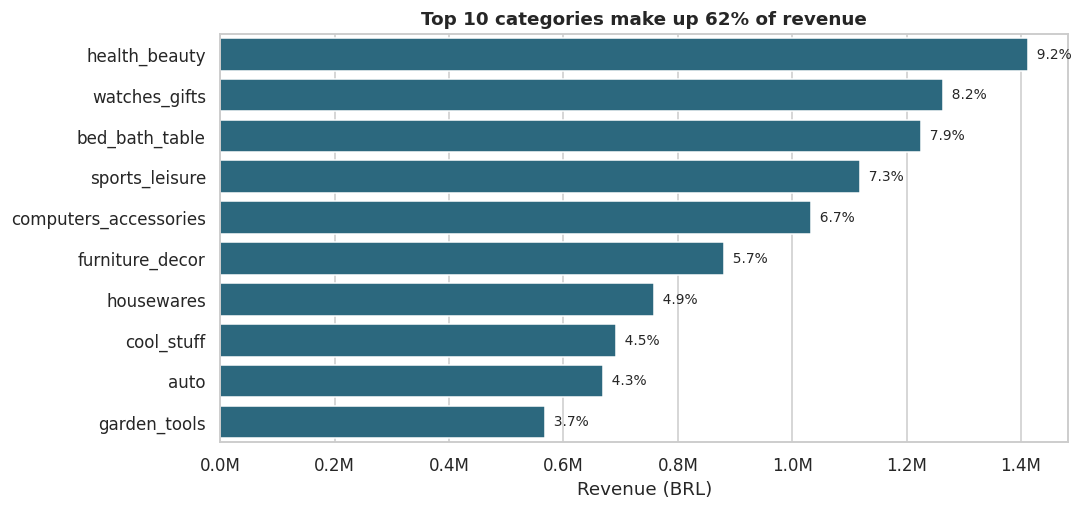

In [5]:
cats = run(3)
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(data=cats, y="category", x="revenue_brl", color="#1f6f8b", ax=ax)
for i, r in cats.iterrows():
    ax.text(r.revenue_brl, i, f"  {r.share_pct}%", va="center", fontsize=9)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
ax.set_xlabel("Revenue (BRL)"); ax.set_ylabel("")
ax.set_title("Top 10 categories make up 62% of revenue", fontweight="bold")
plt.tight_layout(); plt.savefig(IMG + "02_top_categories.png", bbox_inches="tight"); plt.show()

**Finding 2:** Revenue is spread across categories. The top 10 make up 62% of revenue, led by health & beauty, watches & gifts and bed, bath & table. No single category dominates, so the marketplace is not dependent on one product line.

## 3. Do customers come back?

In [6]:
run(4)

Q4. Repeat purchase rate: how many customers ever order again?


,customers,repeat_customers,repeat_rate_pct
0,93358,2801.0,3.0


Q6. Monthly cohort retention (first purchase month vs months since)


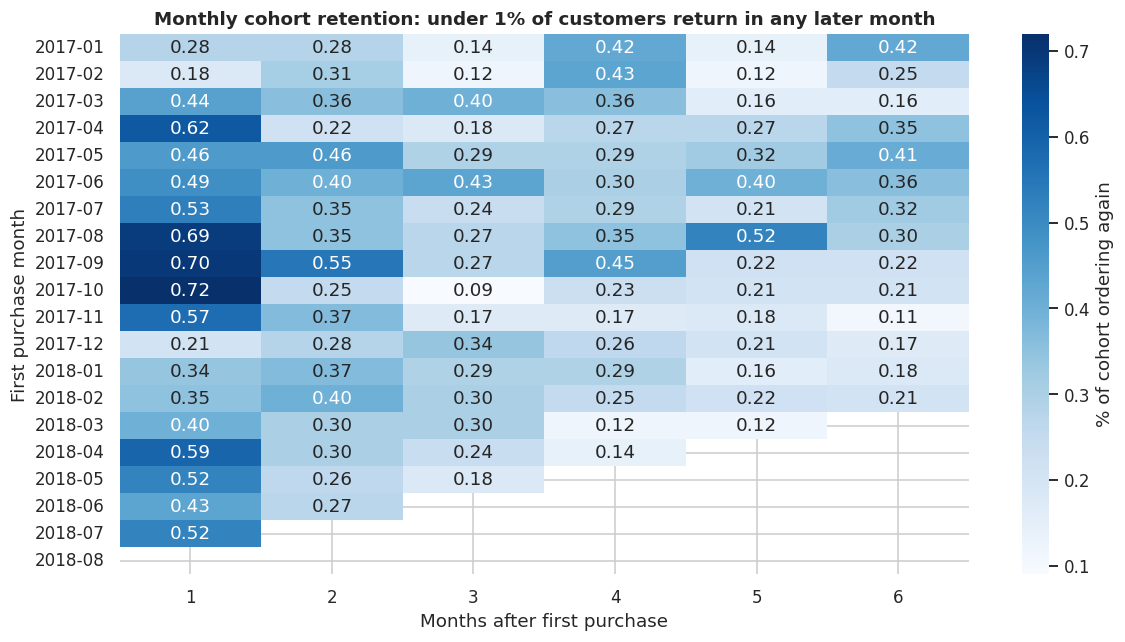

In [7]:
cohort = run(6)
pivot = cohort.pivot(index="cohort_month", columns="month_number", values="retention_pct")
pivot.index = pivot.index.strftime("%Y-%m")
fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(pivot.loc[:, 1:6], annot=True, fmt=".2f", cmap="Blues", cbar_kws={"label": "% of cohort ordering again"}, ax=ax)
ax.set_xlabel("Months after first purchase"); ax.set_ylabel("First purchase month")
ax.set_title("Monthly cohort retention: under 1% of customers return in any later month", fontweight="bold")
plt.tight_layout(); plt.savefig(IMG + "03_cohort_retention.png", bbox_inches="tight"); plt.show()

**Finding 3:** Only **3% of customers ever place a second order**, and in every monthly cohort fewer than 1% return in any given later month. Olist's growth is driven almost entirely by new customers, which is expensive to sustain and explains why growth stalled in 2018.

Q5. RFM segmentation (NTILE quintiles for recency and monetary value)


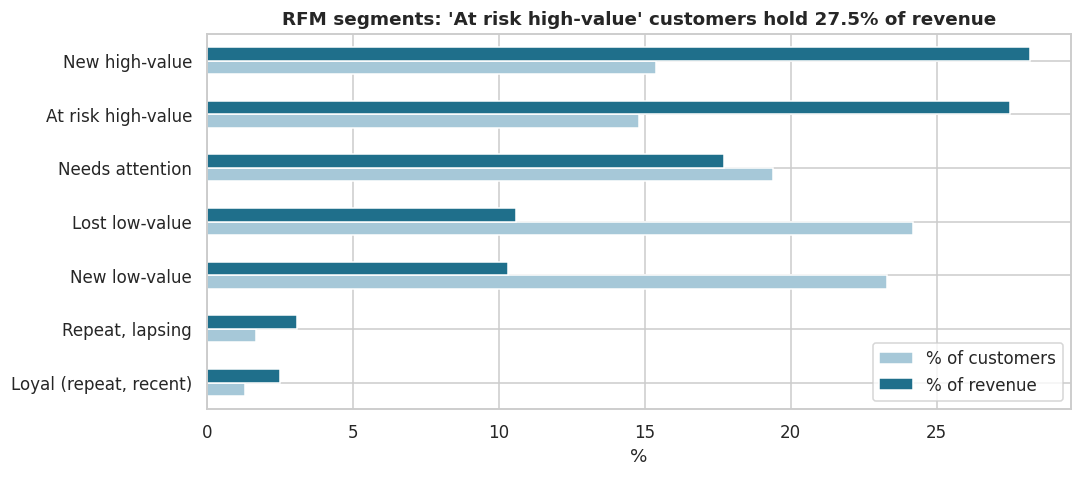

,segment,customers,pct_customers,revenue_brl,pct_revenue,avg_recency_days
0,New high-value,14413,15.4,4354175.0,28.2,91.0
1,At risk high-value,13780,14.8,4240936.0,27.5,393.0
2,Needs attention,18070,19.4,2735970.0,17.7,219.0
3,Lost low-value,22568,24.2,1640578.0,10.6,395.0
4,New low-value,21726,23.3,1583927.0,10.3,89.0
5,"Repeat, lapsing",1598,1.7,476187.0,3.1,319.0
6,"Loyal (repeat, recent)",1203,1.3,388000.0,2.5,88.0


In [8]:
rfm = run(5)
plot = rfm.set_index("segment")[["pct_customers", "pct_revenue"]].sort_values("pct_revenue")
ax = plot.plot(kind="barh", figsize=(10, 4.5), color=["#a6c8d8", "#1f6f8b"])
ax.set_xlabel("%"); ax.set_ylabel("")
ax.legend(["% of customers", "% of revenue"], loc="lower right")
ax.set_title("RFM segments: 'At risk high-value' customers hold 27.5% of revenue", fontweight="bold")
plt.tight_layout(); plt.savefig(IMG + "04_rfm_segments.png", bbox_inches="tight"); plt.show()
rfm

**Finding 4:** Customers were scored on recency and spend (quintiles via `NTILE`) plus whether they bought more than once. The **"At risk high-value"** segment (bought once, over a year ago, in the top 40% of spend) is about 15% of customers but **27.5% of revenue**. These customers already trusted Olist with a large purchase and are the best target for a win-back campaign. Repeat customers are under 3% of the base.

## 4. What hurts customer satisfaction?

Q7. Delivery delay vs customer review score


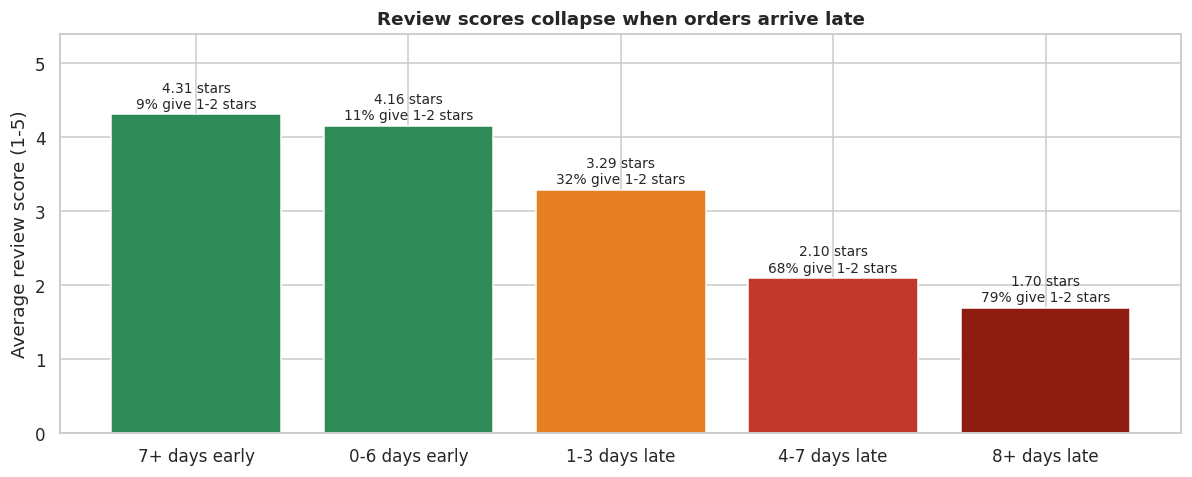

Share of reviewed orders delivered late: 6.7%


In [9]:
delay = run(7)
fig, ax1 = plt.subplots(figsize=(11, 4.5))
colors = ["#2e8b57", "#2e8b57", "#e67e22", "#c0392b", "#8e1b10"]
ax1.bar(delay.delivery_bucket.str[3:], delay.avg_review, color=colors)
for i, r in delay.iterrows():
    ax1.text(i, r.avg_review + 0.08, f"{r.avg_review:.2f} stars\n{r.pct_1_2_star:.0f}% give 1-2 stars", ha="center", fontsize=9)
ax1.set_ylim(0, 5.4); ax1.set_ylabel("Average review score (1-5)")
ax1.set_title("Review scores collapse when orders arrive late", fontweight="bold")
plt.tight_layout(); plt.savefig(IMG + "05_delivery_vs_review.png", bbox_inches="tight"); plt.show()
late_share = delay[delay.delivery_bucket.str.contains("late")].orders.sum() / delay.orders.sum()
print(f"Share of reviewed orders delivered late: {late_share:.1%}")

**Finding 5:** Orders delivered early or on time average **4.2-4.3 stars**. Orders more than a week late average **1.7 stars, and 79% get 1-2 stars**. About 1 in 15 orders (6.7%) arrives late. Because a bad first experience kills the chance of a second order, late delivery is likely part of the retention problem.

Q8. Late-delivery rate by customer state (states with 1,000+ orders)


/tmp/ipykernel_460/3946129974.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=states, x="customer_state", y="late_pct",


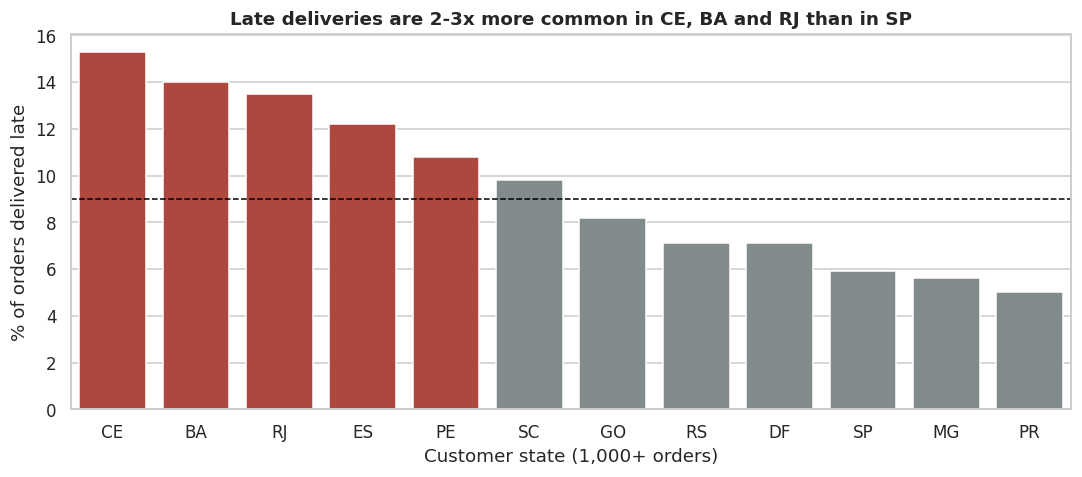

,customer_state,orders,late_pct,avg_delivery_days
0,CE,1279,15.3,21.2
1,BA,3256,14.0,19.3
2,RJ,12350,13.5,15.2
3,ES,1995,12.2,15.7
4,PE,1593,10.8,18.4
5,SC,3546,9.8,14.9
6,GO,1957,8.2,15.5
7,RS,5344,7.1,15.2
8,DF,2080,7.1,12.9
9,SP,40494,5.9,8.7


In [10]:
states = run(8)
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=states, x="customer_state", y="late_pct",
            palette=["#c0392b" if v > 10 else "#7f8c8d" for v in states.late_pct], ax=ax)
ax.axhline(states.late_pct.median(), ls="--", color="black", lw=1)
ax.set_ylabel("% of orders delivered late"); ax.set_xlabel("Customer state (1,000+ orders)")
ax.set_title("Late deliveries are 2-3x more common in CE, BA and RJ than in SP", fontweight="bold")
plt.tight_layout(); plt.savefig(IMG + "06_late_by_state.png", bbox_inches="tight"); plt.show()
states

**Finding 6:** São Paulo (SP), where most sellers are based, has a 5.9% late rate and 8.7-day average delivery. Ceará (CE), Bahia (BA) and Rio de Janeiro (RJ) are late 13-15% of the time. RJ matters most: it is the second-largest market with over 12,000 orders.

In [11]:
run(9)

Q9. Payment methods and instalments


,payment_type,orders,pct_orders,avg_payment_brl,avg_installments
0,credit_card,76505,75.2,163.32,3.5
1,boleto,19784,19.5,145.03,1.0
2,voucher,3866,3.8,65.70,1.0
3,debit_card,1528,1.5,142.57,1.0


**Finding 7:** 75% of orders are paid by credit card, averaging 3.5 instalments. Instalment offers are an important lever for larger purchases.

## 5. Recommendations

1. **Make retention the top priority.** With only 3% repeat buyers, even raising this to 6% would add meaningful revenue without extra acquisition cost. Start with post-purchase emails, a second-order coupon, and category-based recommendations.
2. **Run a win-back campaign for "At risk high-value" customers** (about 13,800 people, 27.5% of revenue). They have already spent heavily once.
3. **Fix delivery estimates and logistics in CE, BA and RJ.** Either improve carrier performance there or set more realistic delivery dates; reviews drop sharply only when orders are late, not when they are slow but on time.
4. **Trigger proactive service on late orders** (an apology message or small voucher) to protect the review and the chance of a repeat purchase.
5. **Plan inventory and marketing around Black Friday,** the strongest month of the year.

## Limitations
- The dataset has no website or cart events, so cart abandonment and conversion funnels cannot be analysed here.
- Data ends in August 2018; later behaviour may differ.
- Review score is one signal of satisfaction; links between delivery and repeat buying are suggested, not proven.